# Table of Contents

## [0] Introduction
- [0A] [Submission Overview](#0a-submission-overview)
- [0B] [Task Distribution](#0b-task-distribution)

## [1] Main File
- [1A] [Initialization](#1a-initialization)
- [1B] [Main Loop](#1b-main-loop)
- [1C] [Conclusion](#1c-conclusion)

## [2] Vision
- [2A] [Module Overview](#2a-module-overview)
- [2B] [Independent Showcase](#2b-independent-showcase)
- [2C] [Deep Dive and Explanation](#2c-deep-dive-and-explanation)
  - [2C-1] [Camera Calibration](#2c-1-camera-calibration)
  - [2C-2] [Real Life Pose Estimation](#2c-2-real-life-pose-estimation-from-camera-frames)
    - [2C-2.1] [Image Acquisition and Undistortion](#2c-21-image-acquisition-and-undistortion)
    - [2C-2.2] [Tag Position Acquisition](#2c-22-tag-position-acquisition)
    - [2C-2.3] [Homography Computation](#2c-23-homography-computation-and-image-flattening)
    - [2C-2.4] [Tag Pose and Velocity Estimation](#2c-24-tag-pose-and-velocity-estimation)
  - [2C-3] [Obstacle Detection](#2c-3-obstacle-detection)
    - [2C-3.1] [Image Preprocessing](#2c-31-image-preprocessing)
    - [2C-3.2] [Contour detection](#2c-32-contour-detection)

## [3] Global Navigation
- [3A] [Module Overview](#3a-module-overview)
- [3B] [Independent Showcase](#3b-independent-showcase)
- [3C] [Deep-Dive & Explanation](#3c-deep-dive--explanation)
  - [3C-1] [Design and Library Choices](#3c-1-design-and-library-choices)
  - [3C-2] [Conceptual Pipeline](#3c-2-conceptual-pipeline)
  - [3C-3] [Rigorous Background](#3c-3-rigorous-background)

## [4] Local Navigation
- [4A] [Module Overview](#4a-module-overview)
- [4B] [Independent Showcase](#4b-independent-showcase)
- [4C] [Deep-Dive & Explanation](#4c-deep-dive--explanation)
  - [4C-1] [Theory and Algorithm](#4c-1-theory-and-algorithm)
  - [4C-2] [Parameter Selection and Tuning](#4c-2-parameter-selection-and-tuning)
  - [4C-3] [Integration with Main System](#4c-3-integration-with-main-system)
  - [4C-4] [Algorithm Flow and Safety Mechanisms](#4c-4-algorithm-flow-and-safety-mechanisms)
  - [4C-5] [Limitations and Future Improvements](#4c-5-limitations-and-future-improvements)

## [5] Extended Kalman Filter (EKF)
- [5A] [Module Overview](#5a-module-overview)
- [5B] [Independent Showcase](#5b-independent-showcase)
- [5C] [Deep Dive & Explanation](#5c-deep-dive--explanation)
  - [5C-1] [Filter Selection](#5c-1-filter-selection)
  - [5C-2] [Motion and Measurement Models](#5c-2-motion-and-measurement-models)
  - [5C-3] [Characterization](#5c-3-characterization)
  - [5C-4] [Implementation](#5c-4-implementation)
  - [5C-5] [Example](#5c-5-example)

## [6] Motion Control (PID)
- [6A] [Module Overview](#6a-module-overview)
- [6B] [Independent Showcase](#6b-independent-showcase)
- [6C] [Deep Dive and Explanation](#6c-deep-dive-and-explanation)
  - [6C-1] [Choice of Controller](#6c-1-choice-of-controller)
  - [6C-2] [Controller Implementation](#6c-2-controller-implementation)
  - [6C-3] [Tuning](#6c-3-tuning)
  - [6C-4] [Example Results](#6c-4-example-results)

## [7] Conclusion and sources
- [7A] [Conclusion](#6a-conclusion)
- [7B] [Sources](#6b-sources)

# [0] Introduction
This report details the design and development of a path-following system using the Thymio robot. The system uses computer vision to detect obstacles in the robot's environment. It then generates a visibility graph using the vertices of these obstacles, and uses the A* algorithm to determine the shortest path to a specified goal point. The robot then travels along this path using a PID controller. It uses an Extended Kalman Filter to estimate state, incorporating robot odometry with computer vision position estimates. If any local obstacles are placed on its path (obstacles that were not accounted for in the global map), the robot detects and avoids them using proximity sensors. Other disturbances the system is able to handle are "kidnapping" (being lifted off the map and moved), and camera covering (therefore losing part of its state estimation).

Demo videos are available on [Google Drive](https://drive.google.com/drive/folders/1-yAhwDbuhh3VsZBCLwUvYRCsoxUqLP8g?usp=drive_link). This folder contains four pairs of videos demonstrating first a typical path, then each of the three disturbances (local obstacle, kidnapping, camera covering). One video in a pair directly shows the robot travelling through the environment. The other shows the screen recording of the control computer, including:
- Obstacle detection
- Path generation
- Live feed of robot path compared to ideal path
- Plots of PID errors, motor inputs, and final robot vs ideal path

## [0A] Submission Overview
The files submitted for this project are organized in the following manner:

```text
├── main.py                          # Top-level file for running the entire robot system
├── constants.py                     # Global constants shared between main and all modules
├── test.py                          # Collection of tests used to characterize the robot and system
├── report.ipynb                       # Report notebook
├── requirements.txt                 # Python dependencies for the system
├── images/                          # Images for the report
├── data collection/                 # Excel files for robot/CV characterization
└── classes/
    ├── cv/                          # Computer vision module
    │   ├── __init__.py
    │   ├── vision.py
    │   └── vision_auxiliary/
    │       ├── camera_calibration.py
    │       ├── camera_calib_param.npz
    │       ├── generate_aruco.py
    │       └── generated_images/
    ├── gp/                          # Global planning module
    │   ├── __init__.py
    │   ├── graph.py
    │   ├── planner.py
    │   ├── plotter.py
    │   └── utils.py
    ├── ekf.py                        # Extended Kalman Filter module
    ├── local_avoidance.py            # Local navigation module
    └── motion_control.py             # Motion control (PID) module
```

## [0B] Task Distribution
The work for this project was distributed among the group members as follows:
- Jiri Blaha: Global planning, kidnapping handling
- Medina Colabrese: Filtering, motion control
- Neyl Essakalli: Local navigation, obstacle avoidance
- Adrien Tarbouriech: Computer vision, global obstacle detection


# [1] Main File
The top-level file for running the entire robot system is `main.py`. This file calls all of the other sub-modules and manages the entire process, from vision initialization to stopping at the end goal. This file contains the function `main()`, which is what is directly run, and many other helper functions to manage all specific actions required.

`main()` first runs all required initialization steps (setting up the robot, computer vision, and global path), and then enters a state machine for the remainder of the program. The possible states are:

- `GLOBAL_NAV`: Normal global navigation behaviour: The robot should be following the generated trajectories, using the filtering and motion control modules to stay on the path.
- `LOCAL_NAV`: Local obstacle avoidance: The robot has sensed an obstacle and must stray from its ideal trajectory to avoid a collision.
- `KIDNAPPED`: The robot has been kidnapped. It is currently travelling through the air, and should no longer be attempting to follow any path.
- `WAIT`: This state runs after a kidnapping has been completed. The robot has a slight delay after being set down, before it recalculates the global path and continues towards the goal.
- `STOP`: The robot has either been forced to stop, or it has reached its final goal. Either way, the program should now end.

The program therefore has three main phases: initialization, main loop, and conclusion.

## [1A] Initialization
The high-level initialization steps performed are as follows:

1. Initialize robot (`init_tdm()`)
    - Wait for connection to robot 
    - Wait for variables to populate
    - Add a variables changed listener (`variables_changed()`). This function ensures that the robot will enter the `STOP` state when middle button is pressed, aborting the program.
2. Initialize computer vision (`init_vision()`)
    - Show window
    - Wait for a press of the 'h' key, then compute locations of corner tags, homography matrix, and locations of obstacles
    - Wait for a press of the 'esc' key to confirm
    - Get robot start and goal positions
    - Convert start position to robot coordinate frame and log
3. Initialize global path (`init_global_path()`, called at the end of `init_vision()`)
    - Call the global planner module to calculate the visibility graph and A* path for the robot to follow
    - Convert path data to robot coordinate frame
4. Initialize control classes (`EKF`, `PID`, `LocalNav`) and set starting variables (goals, state log, etc.)

## [1B] Main Loop
After initialization, the robot runs the following steps on repeat until it enters the `STOP` state.

1. Update live feed
2. Check kidnapping conditions (has the robot newly been picked up/set down)
    - (Note: Kidnapping stops all other functions, and therefore overrides the other states)
    - If it has just been lifted, switch to `KIDNAPPED` state
    - If it has just been set down, switch to `WAIT` state
3. Act appropriately based on current kidnapped state (if applicable)
    - `KIDNAPPED`: Just set the motors to 0
    - `WAIT`: Check if it has completed its wait time. If it has, re-run the following initialization steps to refresh the robot and get a new global path (`wait_after_kidnapping()`):
      - Get new robot pose
      - Update vision to get new obstacles (just in case anything changed)
      - Get a new global path
      - Re-initialize all control classes
4. If not kidnapped, get the current pose and check if we've reached the goal point within the allowed buffer
    - `get_current_pose()` returns the current robot state estimate, after applying an update with the EKF. It does the following:
      - Get the current robot wheel speeds and convert to mm/s
      - Get the current robot position from computer vision
      - If the robot tag isn't currently visible, update the EKF with a very large uncertainty on measurements (increasing the values in the `R` matrix)
      - If the tag is newly visible, update `R` back to its normal values
      - Get the next state from the EKF, using wheel speeds as inputs and CV measurements as measurements
    - `reached_goal()` simply compares the current and goal poses, and returns True/False depending on whether we're within the allowed buffer zone
      - If we've reached an intermediate waypoint, update the goal to the next waypoint in the list
      - If this is the last waypoint (a.k.a. the end goal), set the state to `STOP` to conclude the program
5. Check for any new obstacles detected by the front proximity sensors (`obstacle_detected()`). If so, set state to `LOCAL_NAV`.
6. Act based on navigation state:
    - `GLOBAL_NAV`: Sends the current and goal poses to the PID controller to get the desired motor velocities, then sets the motors.
    - `LOCAL_NAV`: Employs the local navigation edge following process to travel around the obstacle.
7. Sleep for any extra time. 
    - The loop runs at a set time interval (`constants.general['dt']`) to ensure accurate state estimation updates. The processes within the loop have variable runtimes, so `dt` is set to slightly higher than the maximum typical runtime, and the robot sleeps for the remaining time at the end of each loop.

## [1C] Conclusion
The main loop ends when the state is set to `STOP`, either by pressing the center button or reaching the end goal. At this point, the motors are shut off, the vision is closed, and the state and error plots are shown for analysis.

The following is a flowchart representing the data flow of our program:

# [2] Vision
Authored by: Adrien Tarbouriech
## [2A] Module Overview

The Vision module provides all perception for the system: it reads camera frames, removes distortion, detects ArUco markers, flattens the workspace into metric coordinates, and extracts obstacle contours.  
Its output is a clean geometric world description that the Global Navigation module can directly consume.

The pipeline consists of:

1. **Frame Acquisition & Undistortion**  
   The camera feed is captured and corrected using pre-calibrated camera parameters.

2. **Aruco Marker Detection**  
   IDs 0–3 define the workspace corners used to compute a homography and define map boundaries.  
   IDs 4 (Thymio) and 5 (Target) provide robot and goal poses including orientation and velocity.

3. **Homography & Metric Projection**  
   The image is warped to a top-down metric map of size `MAP_W × MAP_H` (mm).  
   All coordinates (poses, contours) are converted to millimeters.

4. **Obstacle Extraction**  
   The flattened map undergoes thresholding, contour extraction, and polygon approximation.  
   Small areas (e.g., ArUco tags) are removed using a minimum-area criterion.

![](./images/cv_pipeline.png)




The module exposes a simple interface via `update_vision()`, which can optionally compute the flat map and obstacles during each frame as well as `update_disp_frame()` to draw on the currently shown frame visual indications of the state of our system.

The vision related files are in the following structure:
```text
classes/cv/
├── __init__.py                 # init
├── vision.py                   # vision
└── vision_auxiliary/
    ├── camera_calibration.py   # script to obtain camera calibration coefficients
    ├── camera_calib_param.npz  # camera calibration coefficients
    ├── generate_aruco.py       # generate A4 page with aruco tags
    └── generated_images/       # folder including images of obstacles and aruco tags
```

## [2B] Independent Showcase
The Vision module can be run entirely standalone to verify detection, flattening, and obstacle extraction without using navigation. Assuming a camera is available, it will run and continuously update the homography and newly created flat image.

A minimal example:

In [ ]:
vision = Vision(0)

while True:
    vision.update_vision(
        save_frames=True,
        find_flat=True,
        find_obstacles=True
    )
    # vision.frame_flat -> top-down map
    # vision.obstacles  -> list of polygon obstacles in mm
    # vision.thymio_pose & target_pose → marker positions

From this we get the sucessive image transformations:

![](./images/raw_to_flat.PNG)

## [2C] Deep dive and explanation
### [2C-1] Camera Calibration

Given the fact that we want to use pixel coordinates on the frames captured by the camera, we have to remove the distortion introduced by the camera physical design. The webcam we are using is a pinhole design, which introduces both radial and tangential distortion.
![](./images/pinhole.PNG)

As shown on the above figure, radial distortion makes straigt lines appear curved more and more as they are from from the image center, whereas tangential distortion makes the image appear closer/farther than it is supposed to.
These optical phenomenons can be modeled through the following formulas:

Radial distortion: 
$$\begin{cases}
x_{\text{distorted}} = x \left( 1 + k_1 r^2 + k_2 r^4 + k_3 r^6 \right) + \left( 2 p_1 x y + p_2 ( r^2 + 2x^2 ) \right), \\[8pt]
y_{\text{distorted}} = y \left( 1 + k_1 r^2 + k_2 r^4 + k_3 r^6 \right) + \left( p_1 ( r^2 + 2y^2 ) + 2 p_2 x y \right)
\end{cases}$$

Tangential distortion:
$$\begin{cases}
x_{\text{distorted}} = x + \left( 2 p_1 x y + p_2 \left( r^2 + 2x^2 \right) \right), \\[6pt]
y_{\text{distorted}} = y + \left( p_1 \left( r^2 + 2y^2 \right) + 2 p_2 x y \right)
\end{cases}$$

As we can see, to obtain the $(x,y)$ coordinates that correspond to real life undistorted coordinates, we have to find the values of distortion coefficients $(k_1 \;\; k_2 \;\; p_1 \;\; p_2 \;\; k_3)$
In addition to these, we have to find the intrinsic parameters specific to our camera, such as focal length $(f_x, f_y)$ and optical centers $(c_x, c_y)$. They allow us to form the camera matrix which enables transformation from real world coordinates to pixel coordinates in the image.

$$
\begin{bmatrix}
x \\
y \\
w
\end{bmatrix}
=
\begin{bmatrix}
f_x & 0   & c_x \\
0   & f_y & c_y \\
0   & 0   & 1
\end{bmatrix}
\begin{bmatrix}
X \\ 
Y \\ 
Z
\end{bmatrix}
$$

To accurately estimate pose from camera frames, the python library OpenCV proposes a camera calibration guide to counteract these distortions. It is based on the use of a ChArUco board, ours being generated by `camera_calibration.py`.
By printing out the ChArUco on a A4 paper and putting it in the field of view of the camera at different angles and distances, we can then take pictures of all the different configurations and use them to calibrate the camera. After taking the pictures and converting to grayscale, cv2.aruco.interpolateCornersCharuco() is used to extract the pixel coordinates of all detected tags for each picture. Then basing itself on basic geometrical equations, cv2.aruco.calibrateCameraCharuco() creates an equation per picture and solves the system to estimate the distortion coefficients and camera matrix.

As a measure of sucess of our calibration, finding a calibration error of $0.4135$ was very reassuring. This corresponds to the RMS reprojection error indicating each predicted ChArUco corner location was off by 0.4 pixels from its detected location, which is excellent.

We note that the code used for camera calibration has been taken from [OpenCV's guide](https://docs.opencv.org/4.x/da/d13/tutorial_aruco_calibration.html) and adapted for our use case.

### [2C-2] Real life pose estimation from camera frames
During our preliminary research for this project, we were faced with the choice of using our method or OpenCV's `cv.solvePnP`. `solvePnp` is an algorithm used for recovering 3D pose from 2D image observations. However our task requires pose estimation from a planar, top-down view of a known map and therefore did not need the additional complexity added with `solvePnp`'s 3rd dimension. Additionally, `solvePnp` would have required more algorithms and processing to obtain the obstacle position and dimensions. With our pipeline, compute a flat map and its associated scale which can then be used for pose estimation and obstacle detection without much further processing.

#### [2C-2.1] Image acquisition and undistortion
We firstly create a video capture object which allows us to capture frames from a live video feed also being displayed in the main loop. Then the following lines optimize the camera matrix parameters for a given frame and then corrects the geometry of the image to remove effects of distortion (using the inverse of the equations mentioned above for radial/tangential distortion).

In [ ]:
def remove_distortion(self, frame):
        h, w = frame.shape[:2]
        new_camera_matrix, _ = cv.getOptimalNewCameraMatrix(self.camera_calib['camera_matrix'],
                                self.camera_calib['dist_coeffs'],(w, h), 1, (w, h))

        undist = cv.undistort(frame, self.camera_calib['camera_matrix'],
                            self.camera_calib['dist_coeffs'], None, new_camera_matrix)
        return undist

#### [2C-2.2] Tag position acquisition
To finally obtain the position of all ArUco tags present in the camera frame acquired and undistorted, we call `.detectMarkers()` from cv2. Since we have specified the exact type of ArUco tags we are using (`cv.aruco.DICT_6X6_50`), `detectMarkers()` is able to run a pattern matching algorithm to identify what is the ID of the tags present in our frame and the pixel coordinates of each corner of the tags. Since the tags are black and white, it firsts converts to grayscale and applies adaptive thresholding to create a clean binary image of our frame. Also knowing the tags are square, it searches for all quadrilateral contours and discards the rest. Then it goes over each potential tag and checks if the detected tag has the same bit patterns as those in the specified dictionnary (`DICT_6X6_50`). In our case, IDs=0-3 correspond to the map corners, ID=4 is on the Thymio and ID=5 is for the target position.

#### [2C-2.3] Homography computation and image flattening
Ideally, we would like the camera to be perfectly parallel and oriented the same way as our map in order to have no perspective tranforming our image, but it is however physically impossible. The next best thing to do is turning to homogenous matrices and homography. If they are correctly computed, they allow to create a map between our view from the camera being placed anywhere around the map at any angle, to a perfectly flat image representing the absolute location of every object present in our frame. The previously shown [figure](./images/raw_to_flat.PNG) in the independent showcase module illustrates the image transformation.


`vision.compute_Homography()` is used to find the matrix H that maps pixels in undistorted space to flat space. Given the pixel coordinates in undistorted space as well as the coordinates each point should be mapped to in the flat space, `cv2.findHomography()` computes the matrix to achieve that mapping. Here is the math behind getting image pixel coordinates $(u,v)$ from real world coordinates $(X_w,Y_W,Z_w)$:
![](./images/pinhole_camera_model.png)

We first convert from real world coordinates to the camera sensor coordinates with the homogenous matrix $\begin{bmatrix}
R & t \\
0 & 1
\end{bmatrix}$ and then to image coordinates with the camera matrix $A$:
$$s \begin{bmatrix}
u \\
v \\
1
\end{bmatrix} = A \begin{bmatrix}
R & t \\
0 & 1
\end{bmatrix} \begin{bmatrix}
X_w \\
Y_w \\
Z_w \\
1
\end{bmatrix}=

\begin{bmatrix}
f_x & 0 & c_x \\
0 & f_y & c_y\\
0 & 0 & 1
\end{bmatrix}

\begin{bmatrix}
r_{11} & r_{12} & r_{13} & t_x \\
r_{21} & r_{22} & r_{23} & t_y \\
r_{31} & r_{32} & r_{33} & t_z
\end{bmatrix}
\begin{bmatrix}
X_w \\
Y_w \\
Z_w \\
1
\end{bmatrix}$$

Because all our markers lie on the same physical plane $Z_w=0$, the equation simplifies into a planar homography that maps any point on the map plane to its appearance in the camera image: $s \begin{bmatrix}
u \\
v \\
1
\end{bmatrix} = H \begin{bmatrix}
X_w \\
Y_w \\
1
\end{bmatrix}$.

Our method `vision.computeHomography()` first filters the detected ArUco markers to keep only IDs 0-3 which define the four corners of the map. Then using the detected corner pixels from `vision.get_tag_positions()` and a set map size of `MAP_W x MAP_H`, `cv.findHomography()` solves for the projection matrix $H$ which best maps the observed marker corners to where they should be on the flat map. Additionally we calculate the scale `vision.scale` used to transform pixel distances into real world milimeter distances. 

Once $H$ is known, we can transform the entire undistorted camera frame using `cv.warpPerspective()`, which applies the homography to all pixels and creates a flat frame where pixel distances can easily be measured to obtain real life distances.


#### [2C-2.4] Tag pose and velocity estimation
Now that we have a way of getting getting real life distances from pixel coordinates of a camera frame, we simply have to track the position of the 4 corners of each tag from which we want to estimate position and angle with respect to the map coordinates.

The method `vision.get_tag_pose(id)` is used to obtain the pose $(x,y,\theta)$ in the following coordinate system:
![](./images/coord_syst_cv.PNG)

By using the already computed tag corner pixel coordinates in the undistorted frame, we then apply to each point the perspective transform using the homography matrix $H$, to give us their positions relative to the flat map. Then, it is as simple as finding $(x_{mean}, y_{mean})$ of the 4 points to obtain the real life center tag position relative to the top left of the map. 
To find the angle of the the tag relative to the y axis and increasing clock-wise, we apply `math.atan2` between the TopLeft and BottomLeft corner of the tag.


The following code is an extract of the method `vision.get_tag_pose()`:

In [ ]:
# compute flat coordinates if homography exists
        if self.H is not None:
            target_corners_flat = cv.perspectiveTransform(pts, self.H)
            target_center_px = target_corners_flat.mean(axis=0)  # in flat units
            target_center_mm = target_center_px * self.scale     # mm units

        # 2D orientation in undistorted image (from corners)
        v = target_corners[0] - target_corners[3]
        theta =  math.atan2(v[1], v[0])

--------------------------------velocity estimation jiri---------------------

### [2C-3] Obstacle detection
Since we are able to compute the pose of objects placed on the map, we decided to use these capabilities and a series of simple image processing steps to extract the pose of our global obstacles as well. We have chosen our obstacles to be black, convex and of $area \geq 100 mm^2$.
![](./images/obstacle_pipeline.PNG)

#### [2C-3.1] Image preprocessing
The subsequent processing stages such as gaussian blurring and adaptive thresholding are intensity based operations and therefore rely on pixel intensity and not color. The colors in the initial frame can lead to variations in the intensity value depending on the lighting conditions for examble, which can lead to inconsistent results. We therefore convert our frame to grayscale as the first step.

Then comes the issue of removing noise in the image. This noise comes from the imperfect sensor of the cheap camera we are using and the inconsistent lighting conditions across the map due to multiple light sources. This generates a lot of small intensity fluctuations across the image that can be interpreted as edges by `cv.adaptiveThreshold()`. 
Several blurring methods could have been used to remove the noise. 
* **Averaging** blur smooths the image by replacing each pixel by the average of its neighbours, but this means its treats all surrounding pixels equally and tends to smear the edges by making them less clear and spreading the black on white contrast to multiple pixels across. 
* **Median blur** is effective at removing salt and pepper noise, but it can round corners instead of keeping them sharp and more simply we have observed to not have this type of noise in our image.
* **Bilateral filtering** is another effective blurring technique introduced in class which blurs the noise while keeping edges sharp, however we decided to not implement it is more computationnaly expensive and proved to perform worse in our tests.
* **Gaussian blurring** is the technique we decided to use. Unlike other filters, it applies a weighted kernel where pixels closer to the center have a higher influence. This removes the high frequency noise all the while keeping the edges sharp for thresholding.

The next key step is adaptive thresholding, the process of converting the grayscale image to a binary image where pixels are either background or obstacle. For regular thresholding operations, pixels are classified as white or black depeding if their intensity is above or below a fixed threshold. In real life this rarely works due to varying lighting intensities and noise. We therefore opted to use `cv.adaptiveThreshold()` which based on the following formula computes a threshold locally for each pixel in order to best classify them. $$T(x, y) = \frac{1}{W \times W} \sum_{(i,j) \in \text{window}} w(i,j) \, I(x+i, y+j) - C $$

To illustrate the effect of blurring the image before thresholding it, can see on the figure above that there are more small white pixel groups that were detected as obstacles when we didn't use gaussian blurring.

Finally, we can apply `cv.morphologyEx()` to remove the small white regions in our frame which were generated by noise or small boundaries meant to be ignored. It works by shrinking the white regions until all small groups of white pixels dissapear, then by dilating again by the same ratio to give back obstacles their original dimensions.

#### [2C-3.2] Contour detection
Once the binary image has been created, all remaining white regions correspond to potential obstacles. We now need to identify these regions, extract their boundaries, and express each obstacle as a polygon defined by its vertices. 
We do this trough `cv.findContours()` which scans the image and returns all contours as a list of points. 
* `cv.RETR_EXTERNAL`: used to only extract the outer contours of each obstacle, since the inside coordinates are irrelevant for our project
* `cv.CHAIN_APPROX_SIMPLE`: is the contour approximation mode, which reduces reduces the number of points used to define vertices. For example instead of storing all points defining a line, it will only preserve the beginning and end points. This reduces further computation and noise sensitivity.

Then, to avoid identifying the ArUco tags as obstacles, we neglect all obstacles of $area \geq 100 mm^2$, since the tags are smaller than that threshold.

The contours obtained directly from the thresholded image contains hundreds of points due to pixel level irregularities and the camera not being in perfect focus. To obtain simple shapes, we approximate each contour with a polygon using `cv.approxPolyDP`.

In [ ]:
def find_obstacle_vertices(self, img):
        # image pre-processing
        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        gray = cv.GaussianBlur(gray, (5, 5), 0)
        threshold = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         cv.THRESH_BINARY_INV, 51, 5)

        # morphology to remove small specks
        kernel = np.ones((3, 3), np.uint8)
        threshold = cv.morphologyEx(threshold, cv.MORPH_OPEN, kernel, iterations=1)
        threshold = cv.dilate(threshold, kernel, iterations=1)

        cv.imwrite("classes/cv/results/debug_threshold.png", threshold)

        # find contours of closed contour polygons
        contours, _ = cv.findContours(threshold, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

        obstacles = []
        obstacle_info_gv = []
        h_c, w_c = gray.shape
        obstacle_info_gv.append(np.array([w_c, h_c]))

        # obstacle must be at least 100x100mm
        min_obstacle_mm = MIN_OBSTACLE_AREA
        if self.scale is None or self.scale == 0:
            min_area_px = 0
        else:
            min_area_px = (min_obstacle_mm / self.scale)**2

        for cont in contours:
            area = cv.contourArea(cont)
            if area < min_area_px:      # discard if area too small <=> ArUco tags
                continue

            perimeter = cv.arcLength(cont, True)
            epsilon = 0.01 * perimeter
            approx = cv.approxPolyDP(cont, epsilon, True)

            if not cv.isContourConvex(approx):
                approx = cv.convexHull(approx)

            approx_px = approx.reshape(-1, 2)
            approx_px_full = approx_px
            if self.scale is not None:
                approx_mm = approx_px_full * self.scale 
            else: approx_mm = approx_px_full

            obstacle_info_gv.append(np.array(approx_mm))

        self.obstacles = obstacle_info_gv.copy()

        debug = img.copy()
        for obs in obstacles:       # save a frame with obstacles for visual representation
            cv.polylines(debug, [obs["vertices_px"].astype(int)], True, (0, 0, 255), 2)
        cv.imwrite("classes/cv/results/debug_obstacles.png", debug)
        return obstacles

This yields the resulting contours displayed on the flat frame:

![](./images/final_results_obstacle.PNG)


# [3] Global Navigation

Authored by: Jiri Blaha

## [3A] Module Overview

The global navigation module transforms the computer vision output into a collision-free reference trajectory. It was designed with modularity in mind, so that it is importable from anywhere. The module is spread accross multiple files for better organization and separation of concerns. The specific directory structure is shown below.

>```txt
>classes/gp/
>├── __init__.py     # init
>├── planner.py      # planning
>├── plotter.py      # plotting
>└── utils.py        # utilities
>```

The main API used for the project are the `GlobalPlanner` and `Plotter` classes. The former houses the general planning functionality, while the latter provides useful plots: either of generated paths, or comparison plots. Import of the aforementioned classes is, as already mentioned, accessible from anywhere within the project using the standard import syntax of the Python language:

In [ ]:
# Module import (API used for the project)
from classes.gp import GlobalPlanner, Plotter

which exposes all the necessary functionality of global planning (and related plotting). This functionality is provided byt the `.plan()` method, owned by `GlobalPlanner`, and the `.path()` method, owned by `Plotter`. For more details, see the [here](./classes/gp/planner.py) and [here](./classes/gp/plotter.py).

## [3B] Independent Showcase

To show the independent functionality of the module, we provide dummy computer vision data below. Generally, the computer vision output (and thereby global planning input) obeys the following structure:

>```python
>cv_data = [
>    [W, H],                                     # map size (width, height)
>    np.array([[obs0_v0], ..., [obs0_vn]]),      # vertices of obstacle 0
>    ...,                                        # vertices of other obs.
>    np.array([[obsM_v0], ..., [obsM_vk]]),      # vertices of obstacle M
>    np.array([s_x, s_y]),                       # start coordinates (x,y)
>    np.array([g_x, g_y])                        # goal coordinates (x,y)
>]
>```

which can be changed to obtain different result, yet we need to be aware of edge cases where for some maps, no path can be found. This issue concerns only unreasonably designed maps, *i.e.*, those with very tight gaps, bad obstacle spacing, etc. All coordinates are in the computer vision frame. Using this information, the planner computes a reference path based on a visibility graph and an A* search.

In [ ]:
import numpy as np

# Load "CV" data
data = [
        [260.0, 200.0],
        np.array([[60, 40], [90, 40], [90, 80], [60, 80]]),
        np.array([[130, 40], [200, 40], [200, 70], [130, 70]]),
        np.array([[120, 120], [160, 120], [160, 170], [120, 170]]),
        np.array([[40, 130], [70, 140], [65, 160], [35, 170], [25, 150]]),
        np.array([[200, 110], [230, 120], [220, 145]]),
        np.array([[180, 10], [230, 15], [225, 35], [175, 30]]),
        np.array([20, 20]),
        np.array([240, 180]),
    ]

Next, let us explore the aforementioned API. First, we need to initialize an instance of both classes. Besides the required `data` argument, the planner can also take additional arguments, namely the Thymio's radius and the spacing of intermediate goals along the reference path. We provide sample values below but note these *do not* represent the final values chosen. The final values can be found [here](./constants.py).

In [ ]:
RADIUS = 2.0    # "Thymio radius" (circumscribed circle)
SPACING = 5.0   # Intermediate goals spacing

# Create GlobalPlanner instance
planner = GlobalPlanner(
    data,
    radius=RADIUS,
    spacing=SPACING
)

# Create Plotter instance
plotter = Plotter(planner)

# Plan and plot path
segments = planner.plan(data)   # plan
plotter.path()                  # plot

Notice that the instance creation of `plotter` requires an instance of `planner`, as can again be seen [here](./classes/gp/plotter.py). With instances created, a reference path can be planned and plotted using the methods mentioned above. It is best to showcase the planning module through a series of plots which best highlight the stages it goes through. Note that these plots were generated on the sample data above and not the actual data. In the figure below, the initial stage produced is the original, plain course without any annotations from `planner`. Next, visibility is introduced (see middle figure), after which we finally generate our reference path using the A* algorithm.

![](./images/planning_stages.svg)

The `GlobalPlanner` class (and its plotting counterpart) naturally extend to real Thymio runs. Besides the already mentioned API, we make use of the architecture in real runs in two other ways. Specifically, the `GlobalPlanner` and `Plotter` allow for:

* Moving the start and replanning from only this information. This functionality is achieved through the `start: Point = None` argument found in the `.plan()` method of `GlobalPlanner`. Specifically, we use this form of planning during kidnapping. We assume the environment Thymio navigates, *i.e.*, the obstacles and goal, stays constant in this state, except for the start.

* Overlaying the EKF estimate, if available, on top of the planned path to see the difference between planning and actual Thymio execution. This is available through the `.paths()` method of the `Plotter` class.

Below we provide examples outputs. The left figure indicates the moving start and is shown for the sample computer vision data. On the other hand, the right figure shows the overlay capability and was captured during an actual run in the testing environment.

![](./images/move_start_and_exec.svg)

## [3C] Deep-Dive & Explanation

This section intends to go deeper into the design considerations and ultimate choices that let the planner become what it is. Further, a concise explanation through mathematical rigor connected to not only the libraries used but also the course material itself is made. 

### [3C-1] Design and Library Choices

The underpinning problem of global navigation is simple. We need to find a shortest reference path around polygonal obstacles for the robot to follow. On one hand, if we consider path planning as merely a pre-processing step, performance is not a main criterion. On the other, when accounting for the kidnapping case, we'd like to find a reference path in the least amount of time in order for us to resume motion without massive delays. Additionally, the question of what do deploy a path finding algorithm on arises as well, among others.

#### Why Visibility Graphs?

As can be inferred from the figures provided, or even from the code, the ultimate choice landed on visibility graphs, yet other canonical approaches were considered as well. Specifically, the following approaches were considered:

* **Occupancy grids**, which provide a uniform and simple structure but lose geometric precision and depend on resolution.

* **Visibility graphs**, which require careful geometric handling but are deterministic and able to provide the exact shortest path.

These consideration made visibility graphs a better choice. To manifest the choice even more, visibility graphs were also chosen since they pair well with robust computational geometry libraries (see later), and, most importantly, they fit our design and objectives best.

#### Why A* over Dijkstra?

The main issue with Dijkstra is that it searches exhaustively with cost only, while the A* algorithm adds a heuristic. As we navigate Euclidean space, the $\ell^2$-norm heuristic was chosen (see later) because it is admissible and consistent. Furthermore, A* search outperforms Dijkstra on visibility graphs with many vertices, which could dramatically reduce time for extreme maps. 

#### Why Inflate Obstacles?

Again, one can infer from the figures (or code) that the initial polygons, provided by computer vision, are being inflated prior to any visibility graph or A* computation. This inflation nothing but a Minkowski sum of the Thymio's radius and the original obstacles. The specific mathematics will be discussed later on, yet from a qualitative standpoint, this is merely an obvious safety measure.

#### Why Shapely/NetworkX?

The [`networkx`](https://networkx.org/en/) and [`shapely`](https://shapely.readthedocs.io/en/stable/)/[`shapely.geometry`](https://shapely.readthedocs.io/en/stable/geometry.html) libraries were chosen mainly for their easy setup, intuitive API, and general functionality they bring to this specific problem. As a nice-to-have, both also provide good documentation. Additionally, both were investigated at the very start of the project and they have proven to work. Planning also uses [`numpy`](https://numpy.org/doc/stable/) and [`matplotlib`](https://matplotlib.org/stable/users/index).

### [3C-2] Conceptual Pipeline

Before diving into mathematics, and with the design choices in mind, the author takes the liberty to outline the high-level flow of information, *i.e.*, to showcase the conceptual pipeline of the planning module. This pipeline has a structure of the form:

1. The computer vision module produces `data` as seen in above code.
2. `GlobalPlanner` inflates polygonal obstacles and creates vertices.
3. `VisibilityGraph` determines valid connections between vertices.
4. `networkx` runs an A* search over the graph from the previous step.
5. Spacing-dependent segments get generated from the previous result.
6. `Plotter` provides visual validation of the found path and segments.

Looking at the broader scope of the project, it is important to note that step 6 is entirely optional and does not enhance any core functinoality. Essentially, the pipeline could end at step 5, when triplets `(x,y,theta)` are passed to the motion control module.

### [3C-3] Rigorous Background

The qualitative reasoning we have developed thus far lets us explore the problem of planning from a more rigorous perspective. Unfortunately, to keep the report within reasonable limits, only the main results we have used are shown in the following text.

#### Geometry and Constraints

Let the map domain be

$$
\Omega = [0,W]\times[0,H]\subset\mathbb{R}^2
$$

where $W$ and $H$ are the width and height of the map, respectively. Additionally, we project the start and goal points, provided by computer vision, into this domain. Given some point $p=(x,y)\in\mathbb{R}^2$, its projection to $\Omega$ is implemented as

$$
x'=\min\{\max\{x,0\}, W\}{,}\quad y'=\min\{\max\{y,0\}, H\}{,}\quad(x',y')\in\Omega
$$

to make sure the planner never reasons about configurations outside the map. For code implementation, see `clamp_point` [here](./classes/gp/planner.py). Furthermore, let the obstacle set provided by the computer vision module be

$$
\mathcal{O} = \{\mathcal{O}_1,\dots,\mathcal{O}_M\}{,}\quad\mathcal{O}_i = \{v_{i_1},\dots,v_{i_{k_i}}\}
$$

where each $\mathcal{O}_i$ is a simple polygon. These polygons partition the map into

$$
\Omega_\mathrm{av} = \Omega\setminus\bigcup\limits_{i=1}^m\mathcal{O}_i\subset\Omega\quad(\subseteq\Omega\ \mathrm{if}\ \mathcal{O}=\emptyset)
$$

wherein we refer to $\Omega_\mathrm{av}$ as available or free space, *i.e.*, what is left of the map for Thymio to navigate.

#### Obstacle Inflation

As discussed before, to create a safety margin for the robot, each polygon is inflated by some $r\geq0$. This is equivalent to

$$
O_i^{(r)} = \mathcal{O}_i\oplus\mathbb{B}_r^{(0)}{,}\quad\mathbb{B}_r^{(0)}=\{x\in\mathbb{R}^2:\lVert x\rVert\leq r\}
$$

where $\mathbb{B}_r^{(0)}$ is a closed disk and the $\oplus$ operator denotes the [Mikowski sum](https://en.wikipedia.org/wiki/Minkowski_addition). The `shapely` library we used computes this via the `.buffer()` method of its `Polygon` class (see [here](./classes/gp/planner.py)), which is nothing but an approximation of the Minkowski sum. Providing `join_style=2` as one of the arguments makes sure to preserve sharp corners of the original polygons. Naturally, the newely constructed shapes provide vertices of the visibility graph after being clamped to the map domain $\Omega$.

#### Visibility Graph

The visibility graph lies at the core of global planning. Let

$$
V = \{v_1,\dots,v_N\}
$$

denote the set of all vertices of all inflated polygons, and eventually the start and goal points. Two arbitrary vertices $a,b\in V$ are connected by an edge if and only if the closed segment (`shapely`'s `LineString`)

$$
[a,b] = \{a+t(b-a):t\in[0,1]\}
$$

satisfies the condition

$$
[a,b]\subseteq\Omega_\mathrm{av}
$$

*i.e.*, lies entirely within the available space. This verification is done using the `.within()` and `.crosses()` methods of the aforementioned `LineString` object (see [here](./classes/gp/graph.py)). Additionally, we allow intersection along the inflated obstacles' boundaries. Subsequently, the visibility graph is stored using `networkx` as a `nx.Graph` object. Formally, it is

$$
G=(V,E){,}\quad E=\{(a,b):a,b\in V, [a,b]\subseteq\Omega_\mathrm{av}\}
$$

with each edge receiving the weight

$$
w(a,b)=\lVert b-a\rVert_2
$$
*i.e.*, a standard Euclidean weight mentioned before.

##### A* Path Search

Let $s,g\in V$ denote the start and goal, respectively. Additonally, let $\mathcal{P}(s,g)$ denote the set of all simple paths in $G=(E,V)$, connecting $s$ to $g$. For any such path $p=(v_0=s,\dots,v_k=g)$, its cost is

$$
g(p) = \sum\limits_{i=0}^{k-1}w(v_i,v_{i+1})
$$

and the objective of global planning is therefore

$$
p^\star = \argmin_{p\in\mathcal{P}(s,g)}g(p)
$$

essentially guiding Dijkstra with an admissible heuristic. For every vertex $x\in V$, define

$$
f(x)=g(x)+h(x)
$$

where $g(x)$ is the cost of the best known path from $s$ to $x$ and $h(x)$ is an estimate of the remaining cost to reach $g$. We choose

$$
h(x) = \lVert x-g\rVert_2
$$
*i.e.*, again, an Euclidean heuristic. As seen in the course, A* expands vertices in order of *lowest* $f(x)$, *i.e.*,

$$
x_\mathrm{next}=\argmin_{x\in\mathcal{X}}f(x)
$$

where $\mathcal{X}$ is the set of still open vertices the path has not reached yet. Notice Dijkstra is recovered from A* by setting $h=0$. All aforementioned mathematics of this subsection is provided by the `.astar_path()` function of `networkx` (see [here](./classes/gp/planner.py)).

#### Segmentation

The A* result is a polyline 

$$
p^\star=(v_0,\dots,v_k){,}\quad v_i=(x_i,y_i)
$$

and in order for us to obtain waypoints, each polyline edge is sampled with $d>0$. For each consecutive pair $v_i, v_{i+1}$, define

$$
\xi = x_{i+1}-x_i{,}\quad\eta = y_{i+1} - y_i{,}\quad\ell_i=\sqrt{\xi^2+\eta^2}{,}
$$

so that samples along the segment are generated for 

$$
t = \frac{kd}{\ell_i}{,}\quad k=1,\dots,\left\lfloor\frac{\ell_i}{d}\right\rfloor
$$

where $\lfloor\cdot\rfloor$ denotes the floor operator. This ensures that an element of $p^\star$ is always the last point in the sequence. We now have

$$
x(t) = x_i+t\xi{,}\quad y(t)=y_i+t\eta{,}\quad\theta_i=\mathrm{atan2}(\eta,\xi)
$$

which we can return as `segments` (see [here](./classes/gp/planner.py) or [here](./main.py)). At a vertex from $p^\star$, we return an average of the previous and next $\theta$.

#### Validation and Plotting

Before running the Thymio, a plot of the reference path is shown (see `plotter.path()` [here](./main.py)) in order to validate the path shape. Because the `Plotter` class is mostly a visualization/utililty tool, the code is self-explanatory and uninteresting, and because we've covered it already in some detail, the author takes the liberty to omit a specific deep-dive and instead refers the reader [here](./classes/gp/plotter.py).

# [4] Local Navigation

Authored by: Neyl Essakalli

## [4A] Module Overview

The local navigation module serves as a reactive safety layer in our autonomous navigation system. While the global planner generates an optimal path from start to goal, the local navigation module ensures the robot can safely navigate around obstacles that were dynamically placed after path planning. The module implements an **edge-following algorithm** that allows the robot to follow obstacle boundaries until it stops seeing the obstacle for a chosen number of iterations, at which point it returns to global navigation state.

The local navigation module is implemented in `classes/local_avoidance.py` and consists of:

- **`LocalNav` class**: Main controller implementing edge-following behavior
- **Helper functions**: Sensor reading and motor control utilities

The module structure is organized as follows:

```
classes/local_avoidance.py
├── LocalNav class
│   ├── __init__()          # Initialize state variables
│   └── follow_edge()        # Main edge-following algorithm
├── read_prox()              # Read proximity sensor values
├── clamp()                  # Utility function for value clamping
└── set_motors()             # Motor control function
```

The main API used for the project is the `LocalNav` class. Import is accessible from anywhere within the project using:

```python
from classes.local_avoidance import LocalNav, read_prox
```

The primary method used is `follow_edge(node, prox)`, which:
- Takes the Thymio node and proximity sensor readings as input
- Returns `True` when the obstacle has been cleared (robot can return to global navigation)
- Returns `False` while still following the obstacle edge

**Key Design Decisions:**

1. **Edge Following vs. Potential Fields**: We chose edge following over potential field methods because:
   - More predictable behavior in cluttered environments
   - Simpler to tune and debug
   - Works well with the Thymio's proximity sensor configuration (The sensors are not optimally placed on the robot as we don't have side sensors)

2. **Proportional Control**: Simple proportional controller for distance maintenance:
   - Fast response time
   - Easy to tune
   - Sufficient for maintaining safe distance from obstacles

3. **Side Selection**: The robot automatically chooses which side of the obstacle to follow based on initial sensor readings, ensuring consistent behavior.

4. **State Machine Integration**: The module integrates seamlessly with the main state machine, transitioning between `GLOBAL_NAV` and `LOCAL_NAV` states based on obstacle detection.


## [4B] Independent Showcase

To show the independent functionality of the module, we provide example code below. The local navigation module can be used standalone to handle obstacle avoidance, requiring only proximity sensor readings as input.

The module expects proximity sensor data in the following format:

>```python
>prox = [val_0, val_1, val_2, val_3, val_4, val_5, val_6]  # 7 sensor values
># where:
># val_0 (IDX_NO):   Far left sensor
># val_1 (IDX_NNO):  Near left sensor
># val_2 (IDX_FRONT): Front center sensor
># val_3 (IDX_NNE):  Near right sensor
># val_4 (IDX_NE):   Far right sensor
># val_5, val_6:     Rear sensors (not used in local navigation)
>```

Sensor values typically range from 0 (no obstacle detected) to ~4000 (very close obstacle). The module uses these readings to determine obstacle presence, select which side to follow, and maintain a safe distance from the obstacle edge.

In [ ]:
from classes.local_avoidance import LocalNav, read_prox

# Initialize LocalNav instance
local_nav = LocalNav()

# Example proximity sensor readings (7 values, range 0-4000)
# High values indicate obstacle presence
prox = [
    2000,  # IDX_NO (0):   Far left sensor - obstacle detected
    1800,  # IDX_NNO (1):  Near left sensor - obstacle detected  
    500,   # IDX_FRONT (2): Front center sensor - clear
    800,   # IDX_NNE (3):  Near right sensor - some obstacle
    600,   # IDX_NE (4):   Far right sensor - minimal obstacle
    0,     # Rear sensors (not used in local navigation)
    0
]

# In actual usage with Thymio robot:
# prox = read_prox(node)  # Read from robot sensors

# Call follow_edge() - returns True when obstacle cleared, False otherwise
# Note: This function also sets motor speeds internally
cleared = await local_nav.follow_edge(node, prox)
# cleared -> False (still following obstacle, will continue in loop)

# After multiple iterations with clear sensor readings:
# cleared -> True (obstacle cleared, can return to global navigation)

The following video demonstrates a successful obstacle avoidance run, showing the robot smoothly navigating around an obstacle and returning to global navigation:

<video width="640" height="480" controls>
  <source src="./images/perfect_avoidance.mov" type="video/quicktime">
  Your browser does not support the video tag.
</video>


## [4C] Deep-Dive & Explanation

This section goes deeper into the design considerations, theoretical background, and implementation details of the local navigation module.

### [4C-1] Theory and Algorithm

#### Edge Following Algorithm

The local navigation module implements a **Bug algorithm variant** known as edge following. This algorithm is part of a family of reactive navigation algorithms that guarantee finding a path if one exists, though not necessarily the optimal path.

**Algorithm Overview:**

1. **Obstacle Detection**: When an obstacle is detected in front of the robot (via proximity sensors), the system switches to local navigation mode.

2. **Side Selection**: The robot determines which side of the obstacle to follow by comparing left and right sensor readings:
   ```
   left_score = left_sensor + front_left_sensor * 0.5
   right_score = right_sensor + front_right_sensor * 0.5
   ```
   The side with higher sensor values (closer obstacle) is chosen, as this typically indicates a more defined edge to follow.

3. **Edge Following**: Using proportional control, the robot maintains a target distance from the obstacle edge:
   ```
   error = target_distance - current_sensor_reading
   turn_adjustment = Kp * error
   ```

4. **Clearance Detection**: The robot continuously monitors if the path ahead is clear. When both the primary and secondary sensors on the following side drop below a threshold for a consistent number of iterations, the obstacle is considered cleared.

5. **Return to Global Navigation**: Once cleared, the robot returns to global navigation mode and continues toward the goal.

#### Sensor Configuration

The Thymio robot has 7 horizontal proximity sensors arranged in an arc. For local navigation, we use the front-facing sensors:

```
Sensor Layout (top view):
     [0]  [1]  [2]  [3]  [4]
      |    |    |    |    |
      NO  NNO  FRONT NNE  NE
```

**Sensor Indices:**
- `IDX_NO` (0): Far left sensor
- `IDX_NNO` (1): Near left sensor  
- `IDX_FRONT` (2): Front center sensor
- `IDX_NNE` (3): Near right sensor
- `IDX_NE` (4): Far right sensor

**Sensor Fusion Strategy:**
For each side (left/right), we use the maximum value of the outer and inner sensors:
```python
left_val = max(left_outer, left_inner)
right_val = max(right_inner, right_outer)
```

This approach:
- Provides more robust readings (less sensitive to sensor noise)
- Better handles cases where the obstacle edge is between sensors
- Reduces false positives from single-sensor noise


#### Proportional Control

The distance maintenance uses a simple proportional controller:

**Control Law:**
```
error = target_distance - measured_distance
differential_speed = Kp * error * turn_speed
```

Where:
- `target_distance`: Desired distance from obstacle (stored in `constants.local_avoidance['target_side_value']`)
- `measured_distance`: Current sensor reading on the following side
- `Kp`: Proportional gain (`constants.local_avoidance['proportional_gain']`)
- `turn_speed`: Base turning speed multiplier

**Motor Speed Calculation:**
- When following left edge: turn right when too close, turn left when too far
- When following right edge: turn left when too close, turn right when too far

```python
if following_left:
    left_speed = forward_speed - diff
    right_speed = forward_speed + diff
else:  # following_right
    left_speed = forward_speed + diff
    right_speed = forward_speed - diff
```

**Safety Constraints:**
- Maximum differential speed is limited to 80% of forward speed to prevent in-place turning
- All motor speeds are clamped to [-500, 500] (Thymio motor limits)
- Emergency backup if front sensor exceeds threshold


### [4C-2] Parameter Selection and Tuning

All parameters are stored in `constants.py` under the `local_avoidance` dictionary:

```python
local_avoidance = {
    'front_threshold': 1600,        # Obstacle detection threshold (front sensor) for back manoeuver
    'clear_threshold': 800,          # Clearance detection threshold
    'forward_speed': 160,            # Base forward speed during edge following
    'turn_speed': 130,               # Base turning speed multiplier
    'proportional_gain': 0.01,      # Proportional control gain (Kp)
    'target_side_value': 1200,       # Target distance from obstacle edge
    'exit_consistent_count': 5,      # Iterations of clear readings before exit
    'detection_threshold': 1800,     # Threshold for entering local nav mode
    'side_threshold': 1000,          # Side sensor threshold
}
```

**Parameter Tuning Process:**

**1. Detection Threshold (`detection_threshold`):**
- **Value:** 1800
- **Rationale:** Must be high enough to detect obstacles early but not trigger on sensor noise
- **Testing:** Verified through multiple obstacle encounters at various distances
- **Trade-off:** Lower values = earlier detection but more false positives

**2. Target Side Value (`target_side_value`):**
- **Value:** 1200
- **Rationale:** Balance between:
  - Close enough to follow the edge accurately
  - Far enough to avoid collisions
  - Within sensor's reliable range (typically 0-4000)
- **Measurement:** Tested with obstacles of various shapes; 1200 provides stable following

**3. Proportional Gain (`proportional_gain`):**
- **Value:** 0.01
- **Rationale:** Provides responsive control while maintaining stability
- **Tuning Method:** Adjusted with the agressivness of the turns
- **Result:** Smooth distance maintenance with good responsiveness

**4. Forward Speed (`forward_speed`):**
- **Value:** 160
- **Rationale:** Slower than global navigation (130*2/3 ≈ 87) to allow:
  - Better sensor readings
  - More time to react to edge changes
  - Safer navigation near obstacles

**5. Turn Speed (`turn_speed`):**
- **Value:** 130
- **Rationale:** Base multiplier for turning adjustments in proportional control
- **Tuning Method:** Reduced from 160 to match the proportional gain increase, maintaining balanced control
- **Result:** Provides appropriate turning responsiveness without excessive corrections

**6. Exit Consistent Count (`exit_consistent_count`):**
- **Value:** 5 iterations
- **Rationale:** Prevents premature exit due to sensor noise
- **Calculation:** At dt=0.18s, 5 iterations ≈ 0.9 seconds of clear readings
- **Testing:** Verified prevents false exits while allowing timely return to global nav

**7. Clear Threshold (`clear_threshold`):**
- **Value:** 800
- **Rationale:** Lower than target_side_value to ensure significant clearance
- **Safety Margin:** ~33% below target distance provides buffer for re-entry to global nav

**8. Front Threshold (`front_threshold`):**
- **Value:** 1600
- **Rationale:** Low threshold to back-up when too close to the obstacle and risk of touching too high
- **Testing:** Lower the threshold until the robot started going back everytime without contourning
- **Result:** Robot reacts well when obstacle put right in front of him


The following video illustrates what happens when `front_threshold` is set too low. The robot gets stuck in a back-and-forth motion, continuously backing up and moving forward without successfully navigating around the obstacle. This demonstrates the importance of proper threshold tuning:

<video width="640" height="480" controls>
  <source src="./images/low_front_threshold.mov" type="video/quicktime">
  Your browser does not support the video tag.
</video>


### [4C-3] Integration with Main System

The local navigation module integrates with the main state machine in `main.py`. The system operates in two primary navigation states:

1. **`GLOBAL_NAV`**: Robot follows the planned path 
2. **`LOCAL_NAV`**: Robot follows obstacle edges using the local navigation module

**State Transitions:**

```python
# Detection triggers transition to local navigation
if obstacle_detected(prox) and state == State.GLOBAL_NAV:
    state = State.LOCAL_NAV

# Clearance triggers return to global navigation  
cleared = await local_nav.follow_edge(node, prox)
if cleared:
    state = State.GLOBAL_NAV
```

**Obstacle Detection Function:**
The `obstacle_detected()` function checks multiple front-facing sensors:
```python
detection_threshold = constants.local_avoidance['detection_threshold']
return (front >= threshold or 
        front_left >= threshold or 
        front_right >= threshold or
        far_left >= threshold or
        far_right >= threshold)
```

This multi-sensor approach ensures robust detection even when obstacles are not directly in front of the robot.

**Motor Control Interface:**

The local navigation module uses a different motor control interface than global navigation:

- **Global Navigation**: Uses `set_motors(left_vel, right_vel)` which takes linear velocities in mm/s
- **Local Navigation**: Uses `set_motors(node, left, right)` which takes direct motor values (-500 to 500)

This difference exists because:
1. Local navigation needs direct motor control for precise edge following
2. The proportional control calculations are done in motor units for simplicity
3. Safety constraints (backing up) are easier to implement with direct motor values

**Motor Value Conversion:**
The Thymio motor values range from -500 to 500, where:
- Positive values: Forward rotation
- Negative values: Backward rotation
- Magnitude: Speed (0 = stopped, 500 = maximum speed)


### [4C-4] Algorithm Flow and Safety Mechanisms

**Algorithm Flow:**

The complete edge-following algorithm flow is as follows:

```
1. INITIALIZATION
   ├─ clear_count = 0
   └─ follow_side = None

2. SENSOR READING
   ├─ Read all proximity sensors
   └─ Compute left_val, right_val, front_val

3. SIDE SELECTION (first iteration only)
   ├─ Calculate left_score = left_val + left_inner * 0.5
   ├─ Calculate right_score = right_val + right_inner * 0.5
   └─ Choose side with higher score

4. DISTANCE CONTROL
   ├─ error = target_distance - sensor_reading
   ├─ diff = Kp * error * turn_speed
   ├─ Limit diff to prevent in-place turning
   └─ Calculate motor speeds based on side

5. SAFETY CHECK
   └─ If too close to front: BACK UP
      Else: Apply calculated motor speeds

6. CLEARANCE DETECTION
   ├─ If sensors below threshold: increment clear_count
   └─ If clear_count >= exit_count: RETURN TRUE
      Else: RETURN FALSE
```

**Safety Mechanisms:**

**1. Emergency Backup:**
```python
if front_val > constants.local_avoidance['front_threshold'] * 1.1:
    await set_motors(node, -120, -120)
```
- Triggers when front sensor exceeds 110% of detection threshold
- Robot backs up at moderate speed (-120) to create clearance
- Prevents collision when approaching obstacle too quickly

**2. Differential Speed Limiting:**
```python
max_diff = constants.local_avoidance['forward_speed'] * 0.8
diff = clamp(diff, -max_diff, max_diff)
```
- Prevents in-place turning (one motor forward, one backward)
- Ensures robot always makes forward progress
- 80% limit allows sharp turns while maintaining forward motion

**3. Motor Value Clamping:**
```python
left_speed = clamp(left_speed, -500, 500)
right_speed = clamp(right_speed, -500, 500)
```
- Enforces Thymio hardware limits
- Prevents invalid motor commands

**Clearance Detection Strategy:**

The clearance detection uses a **consistency-based approach**:

```python
if sensor1 < clear_threshold and sensor2 < clear_threshold:
    clear_count += 1
else:
    clear_count = 0

cleared = clear_count >= exit_consistent_count
```

**Why this approach?**

1. **Noise Immunity**: Single low reading could be sensor noise; multiple consistent readings indicate true clearance
2. **Hysteresis**: Prevents rapid oscillation between local/global navigation states
3. **Dual Sensor Check**: Uses both primary and secondary sensors on the following side for robustness

**Parameter Selection:**
- `exit_consistent_count = 5`: At dt=0.18s, this equals ~0.9 seconds of clear readings
- `clear_threshold = 800`: 33% below target distance provides safety margin
- This combination prevents false exits while allowing timely return to global navigation


### [4C-5] Limitations and Future Improvements

**Current Limitations:**

1. **Convex Obstacles Only**: The algorithm works best with convex obstacles. Concave obstacles may trap the robot in local minima.

2. **No Memory**: The robot doesn't remember which obstacles it has already encountered, potentially causing repeated navigation around the same obstacle. (Doesn't happen after tuning)

3. **Fixed Parameters**: All parameters are static. Adaptive tuning based on obstacle type could improve performance.

4. **Single Side Following**: Once a side is chosen, the robot doesn't reconsider. In some cases, the other side might be more efficient.

5. **Touching after clearing**: Sometimes, when the next point in global path is behind the local obstacle, the robot can touch the local obstacle after avoiding.

**Potential Improvements:**

1. **Bug2 Algorithm**: Implement the Bug2 algorithm which maintains a line to the goal, potentially finding shorter paths.

2. **Obstacle Memory**: Track encountered obstacles to avoid repeated navigation.

3. **Dynamic Side Switching**: Allow switching sides if the current side becomes blocked.

4. **Better Exit Strategy**: Find a better way to get away from the obstacle before returning into global navigation.


# [5] Extended Kalman Filter
Authored by: Medina Colabrese
## [5A] Module Overview
An Extended Kalman Filter was implemented for state estimation of the robot. This filter combines robot position (x, y, and angle) measurements from the computer vision with a basic two-wheel differential robot motion model for state estimation, using motor speeds produced from the PID controller (next section) as inputs.

The code for the EKF is located in `classes/ekf.py`. To use it, an instance of the `EKF` class must be initialized with the following parameters:
- Motion model error covarince matrix `Q`
- Measurement model error covariance matrix `R`
- Initial state
- Robot wheel-to-wheel width (used in the motion model) `T`
- Time step `dt`

After initialization, the next state can be calculated by calling the function `generate_next_state(inputs, measures)`, which takes as parameters the system inputs (motor velocities) and measurements (positions from CV) at the current time.

## [5B] Independent Showcase
The following code blocks provide a simple simulation demonstrating the functionality of the EKF. At each time step, the robot is provided with a random input. Its next state is moved according to the motion model and measurements are generated at each step, with noise added based on the measured variances (see next subsection).

We first import the required modules, select the starting pose of the robot, and initialize the EKF.

In [1]:
from classes.ekf import EKF
import constants
import numpy as np
import matplotlib.pyplot as plt
import random

# Set start at the origin
# State takes the form [x, y, v, theta, w]
start_pose = [0., 0., 0., 0., 0.]
dt = constants.general['dt']

# Initialize EKF
ekf = EKF(
    np.diag(constants.ekf['move_vars']), # Q
    np.diag(constants.ekf['measure_vars']), # R
    start_pose,
    constants.robot['wheel_base'],
    dt
)

We can then run the entire loop, which takes the following steps:
- Get the ideal measurements (the exact current state), then add noise based on the proper measurement variance
- Get the state estimate from the EKF
- Pick a set of random inputs to apply
- Update the real state using these inputs, and add noise based on the proper motion model variance

In [14]:
# Logs for plotting later
real_pose_log = [start_pose]
ekf_pose_log = []

# Initial inputs are 0
left_mtr = 0
right_mtr = 0

iters = 100
for n in range(iters):
    prev_pose = real_pose_log[-1]

    # Get ideal measurements from current state (x, y, theta)
    measures_ideal = [prev_pose[0], prev_pose[1], prev_pose[3]]

    # Add noise based on measured variances (constants.ekf['measure_vars'])
    measures_noisy = measures_ideal
    for i in range(len(measures_noisy)):
        measures_noisy[i] += random.gauss(0, np.sqrt(constants.ekf['measure_vars'][i]))

    # Get state estimate from EKF
    est_pose, cov_matrix = ekf.generate_next_state(
                inputs=[left_mtr, right_mtr],
                measures=measures_noisy
                )
    ekf_pose_log.append(est_pose)

    # Break if we're at the last step, we don't care about the last position
    if n == iters-1:
        break

    # Pick new random inputs based on our normal driving velocity ranges
    left_mtr = random.randrange(50, 150)
    right_mtr = random.randrange(50, 150)

    # Calculate linear and angular velocity for simulation purposes
    v = (left_mtr + right_mtr)/2
    w = (right_mtr - left_mtr)/constants.robot['wheel_base']

    # Calculate theoretical next state
    prev_x, prev_y, prev_v, prev_theta, prev_w = real_pose_log[-1]

    next_x = prev_x + v*np.cos(prev_theta)*dt
    next_y = prev_y + v*np.sin(prev_theta)*dt
    next_theta = prev_theta + w*dt

    real_pose_nonoise = [next_x, next_y, v, next_theta, w]

    # Add noise
    real_pose = real_pose_nonoise
    for i in range(len(real_pose)):
        real_pose[i] += random.gauss(0, np.sqrt(constants.ekf['move_vars'][i]))

    real_pose_log.append(real_pose)



Finally, we plot the real and estimated state.

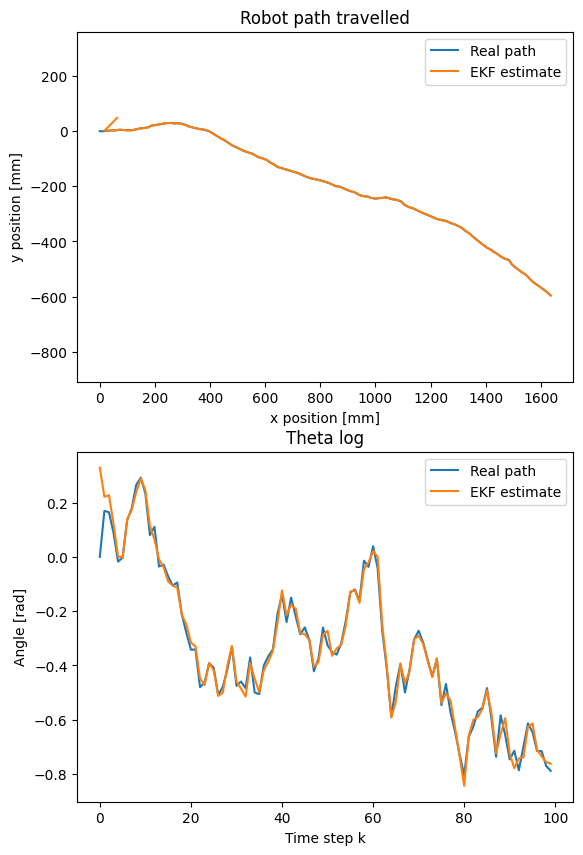

In [15]:
# Plot path
x_log_real = [state[0] for state in real_pose_log] 
y_log_real = [state[1] for state in real_pose_log]
theta_log_real = [state[3] for state in real_pose_log]

x_log_ekf = [state[0] for state in ekf_pose_log] 
y_log_ekf = [state[1] for state in ekf_pose_log]
theta_log_ekf = [state[3] for state in ekf_pose_log]


plt.figure(figsize=[6.4, 10])
plt.subplot(2, 1, 1)
plt.plot(x_log_real, y_log_real)
plt.plot(x_log_ekf, y_log_ekf)
plt.title("Robot path travelled")
plt.legend(["Real path", "EKF estimate"])
plt.xlabel("x position [mm]")
plt.ylabel("y position [mm]")
plt.axis('equal')

plt.subplot(2, 1, 2)
plt.plot(theta_log_real)
plt.plot(theta_log_ekf)
plt.legend(["Real path", "EKF estimate"])
plt.title("Theta log")
plt.xlabel("Time step k")
plt.ylabel("Angle [rad]")
plt.show()

## [5C] Deep Dive & Explanation
### [5C-1] Filter Selection
The three types of filtering for localization taught in class were the histogram filter, particle filter, and Kalman filter. Of these three, we decided that a Kalman filter would be the best fit for our scenario. 

Using a histogram filter would have involved discretizing the entire map into a fine enough grid to provide high-accuracy localization - on the order of millimeters. Splitting our map of size 890 x 1260 mm into even 5 mm square sections would require storing and recalculating $(890/5)*(1260/5) = 44856$ different probabilities each timestep, using a large amount of processing power for what would still be an inaccurate state estimate (and this is only including x and y position as state variables). This was clearly not an ideal solution.

A particle filter is a lower-cost version of the histogram filter, prioritizing likelihood calculations for only the most probable states. However, this still has a much higher computational cost than a Kalman filter, and likely a lower accuracy (depending on the size of the discretization step). 

In terms of computing power and accuracy, a Kalman filter is the best obvious choice. There are two main concerns with using a Kalman filter. First of all, the generic Kalman filter can only work with linear systems, so an Extended Kalman Filter (EKF) would need to be used instead. This is slightly more complex, as it requires calculating Jacobians of the motion and measurement model matrices, and would lose accuracy on highly nonlinear systems. We assumed, however, that the two-wheel differential drive equations of motion are simple enough that an EKF would still perform well (i.e. these equations are not "highly nonlinear").

The other, more important drawback of using an EKF is that it assumes the measurement and motion model errors follow a Gaussian distribution. Before the EKF could be reliably implemented and used, it had to be shown that this assumption was true.

### [5C-2] Motion and Measurement Models

The Thymio robot is a two-wheel differential drive robot. If we know the linear speeds of each wheel at a given timestep $k$ ($v^l_k$ and $v^r_k$ for the left and right wheels, respectively), and that the robot has a distance of $T$ between the two wheels, then the velocity and angular velocities of the robot in the global frame are:

$$
v_k = \frac{v^l_k + v^r_k}{2}, \quad
\omega_k = \frac{v^r_k - v^l_k}{T}
$$

Using a first-order Taylor series approximation, the $x$, $y$, and $\theta$ states of the robot can therefore be updated from the previous state using the following equations:

$$
x_k = x_{k-1} + v_{k-1} \cos(\theta_{k-1}) \, dt
$$

$$
y_k = y_{k-1} + v_{k-1} \sin(\theta_{k-1}) \, dt
$$

$$
\theta_k = \theta_{k-1} + \omega_{k-1} \, dt
$$

We use the state variable $\mu = [x, y, v, \theta, \omega]^T$. Therefore, the measurement model function $g(\mu_{k-1}, u_t)$ (where $\mu_{k-1}$ is the previous state and $u_t$ is the current input) is defined as:

$$
g(\mu_{k-1}, u_t) =
\begin{bmatrix}
x_{k-1} + v_{k-1} \cos(\theta_{k-1}) \, dt \\
y_{k-1} + v_{k-1} \sin(\theta_{k-1}) \, dt \\
\frac{v^l_k + v^r_k}{2} \\ 
\theta_{k-1} + \omega_{k-1} \, dt \\
\frac{v^r_k - v^l_k}{T}
\end{bmatrix}
=
\begin{bmatrix}
\mu^{(0)}_{k-1} + \mu^{(2)}_{k-1} \cos(\mu^{(3)}_{k-1}) \, dt \\
\mu^{(1)}_{k-1} + \mu^{(2)}_{k-1} \sin(\mu^{(3)}_{k-1}) \, dt \\
\frac{u^{(0)}_k + u^{(1)}_k}{2} \\ 
\mu^{(3)}_{k-1}+ \mu^{(4)}_{k-1} \, dt \\
\frac{u^{(1)}_k - u^{(0)}_k}{T}
\end{bmatrix}
$$

The measurement model is implemented in `ekf.py` in the `motion()` function:


In [ ]:
# Apply motion model to get belief of next state
def motion(self, x, u):
    px0, py0, v0, th0, w0 = x[0], x[1], x[2], x[3], x[4]
    vl, vr = u[0], u[1]
    dt, T = self.dt, self.T

    px1 = px0 + v0*cos(th0)*dt
    py1 = py0 + v0*sin(th0)*dt
    v1 = (vl + vr)/2
    th1 = th0 + w0*dt
    w1 = (vr - vl)/T

    return np.array([px1, py1, v1, th1, w1])

The Jacobian of the motion model with respect to the state $\mu$ is denoted as $G(\mu_{k-1})$. It contains the partial derivatives of each function in $g$ with respect to each state variable:

$$
G(\mu_{k-1}) =
\begin{bmatrix}
\frac{\partial g_1}{\partial \mu_{k-1}} \\
\frac{\partial g_2}{\partial \mu_{k-1}} \\
\frac{\partial g_3}{\partial \mu_{k-1}} \\
\frac{\partial g_4}{\partial \mu_{k-1}} \\
\frac{\partial g_5}{\partial \mu_{k-1}}
\end{bmatrix}
=
\begin{bmatrix}
1 & 0 & \cos(\theta_{k-1}) \, dt & -v_{k-1}\sin(\theta_{k-1}) \, dt & 0 \\
0 & 1 & \sin(\theta_{k-1}) \, dt & v_{k-1}\cos(\theta_{k-1}) \, dt & 0 \\
0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 & dt \\
0 & 0 & 0 & 0 & 0
\end{bmatrix}
$$

This is implemened in `ekf.py()` in the `motion_jac()` function:

In [ ]:
# Motion model Jacobian
def motion_jac(self, x, u):
    px0, py0, v0, th0, w0 = self.state[0], self.state[1], self.state[2], self.state[3], self.state[4]
    dt, T = self.dt, self.T

    return np.array([
        [1,     0,      cos(th0)*dt,        -v0*sin(th0)*dt,         0],
        [0,     1,      sin(th0)*dt,        v0*cos(th0)*dt,          0],
        [0,     0,      0,                  0,                       0],
        [0,     0,      0,                  1,                       dt],
        [0,     0,      0,                  0,                       0]
    ])

The measurement model is simpler. We measure $x$, $y$, and $\theta$ directly from the computer vision system. The measurement function $h(\mu_{k-1})$ is:

$$
h(\mu_{k-1}) =
\begin{bmatrix}
x_{k-1} \\
y_{k-1} \\
\theta_{k-1}
\end{bmatrix}
=
\begin{bmatrix}
\mu^{(0)}_{k-1} \\
\mu^{(1)}_{k-1} \\
\mu^{(3)}_{k-1}
\end{bmatrix}
$$

The Jacobian of the measurement model with respect to the state $\mu_{k-1}$ is:

$$
H(\mu_{k-1}) =
\begin{bmatrix}
\frac{\partial h_1}{\partial \mu_{k-1}} \\
\frac{\partial h_2}{\partial \mu_{k-1}} \\
\frac{\partial h_3}{\partial \mu_{k-1}}
\end{bmatrix}
=
\begin{bmatrix}
1 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 & 0
\end{bmatrix}
$$

These are implemented in `ekf.py()` in the `measure()` and `measure_jac()` functions, respectively:

In [21]:
# Apply measurement model to get expected measurements for the state
def measure(self, x):
    return np.array([x[0], x[1], x[3]])

# Measurement model Jacobian
def measure_jac(self, x):
    return np.array([
        [1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 0, 1, 0],
    ])

### [5C-3] Characterization
Before applying the EKF equations above, we had to characterize the variances of each equation in the motion and measurement models, and confirm the errors formed Gaussian distributions. We also had to determine a conversion between linear speed in mm/s, and motor speed in Thymio units. 

We first tested the error magnitude and variance of the computer vision position estimates, to determine if they were accurate enough to be used as a "ground truth" for robot characterization. For x and y position, we placed a point at a known location in the center of the map. The CV estimate should be most accurate there, as it is directly below the camera and undergoes the least distortion. We then took 216 repeated measurements. (Note: We decided to take all of our measurements at one location, because we observed in earlier tests that the error in our manual measurements was creating a multimodal distribution due to different constant errors at each location).

To measure the angular error, we again centred a tag, then took several measurements at each angle in between 0 and 360 degrees (with steps of 20 degrees). We repeated this at three different locations spread across the map.

This data is available in `data collection/cv_variances.xlsx`. The images below show the distributions of these three error measurements. They are each roughly Gaussian, which is the first step in validating the choice of EKF for localization. The variances were:
- x: 0.364 mm
- y: 0.213 mm
- $\theta$: 0.000505 rad

giving a measurement covariance matrix of 
$$
R = \begin{bmatrix}
0.364 & 0 & 0 \\
0 & 0.213 & 0 \\
0 & 0 & 0.00051
\end{bmatrix}
$$

Note that it was assumed these variables are each independent. 

![](images/cv_errors.png)

Next, we ran a test to determine the conversion between linear speed in mm/s and speed in Thymio units. We decided to use the computer vision as a measurement model, as based on the previous error variance results, we estimated that this was much more accurate than what we could achieve manually, and allowed us to skip the acceleration period.

All of our robot characterization tests are located in `tests.py`. The function used for this test is `test_velocity_to_motor_input()`. This test follows the following steps:
1. Initialize vision
2. Set a list of robot speeds to test, and a runtime at each speed
3. Set the motors to the first speed (in Thymio units)
4. Wait 1 second to account for acceleration
5. Store the current robot position and timestamp
6. Wait for the specified delay time
7. Store the end robot position and new timestamp
8. Turn off the motors
9. Calculate the distance travelled using the CV positions, then calculate real-world velocity using this distance and the stored timestamps
10. Log the pair of speeds (Thymio units & mm/s)

We first calibrated the Thymio to ensure it drove straight, using the process described [in the documentation](http://aseba.wikidot.com/fr:thymiomotorcalibration). This calibration mode allows the user to adjust the left and right gains for the two motors by pressing the two side buttons on the top of the robot. As the robot moved, we adjusted the gains until it drove straight, verifying this calibration at several different speeds.

After calibration, we ran our test function several times at a variety of different speeds, then performed linear regression in Excel to determine a conversion. The data is located in `data collection/motor-speed-calibration.xlsx`. This produced the following plot, and the relationship `real_speed = 0.3664*thymio_speed` with an $R^2=0.9994$ (nearly a perfect fit).

![](images/mtr_speed_calibration.png)

Finally, we ran a series of characterization tests to determine the variances of the five state variables from the motion model. These tests are located in the `test_linear_variances()` and `test_angular_variances()` functions of `test.py`. 

For the linear variances, the steps followed were:
1. Initialize vision
2. Start robot motors
3. Wait 1 second to account for acceleration
4. Log the current time and robot pose, then add a slight delay
5. At each timestep for the specified test time:
6. Log the current timestep and robot pose
7. Get the robot's two wheel speeds, and calculate velocity from the average of the two
8. Calculate velocity error as the difference between the set and measured velocities
9. Calculate two different estimates of position, one from CV (as a "ground truth") and one from robot odometry (imitating the EKF motion model). CV calculates the Euler distance to the previous pose, and the robot uses $velocity*\Delta t$. 
10. Calculate the positional error as the difference between these two, and log.

The steps followed for angular variances were nearly the same. The two robot wheels were set to different speeds to produce a known (theoretical) angular velocity, and the absolute angle $\theta$ of the robot was measured from CV instead of the distance travelled.

These tests gave four variances: linear and angular positions and velocities. There are five state variables, as linear position has  $x$ and $y$ components. It was assumed that the variances for both of these components would be the same, as the robot should theoretically perform the same regardless of which direction it is facing.

The data acquired from these tests is provided in `data collection/robot-variances.xlsx`. It produced the plots showed below. As we can see, each plot follows a roughly Gaussian distribution. This confirms that everything being modelled (measurements and motion) follow a Gaussian error distribution, therefore validating the choice of an EKF.

The variances of each measurement are:
- Position: 4.48 mm
- Velocity: 10.78 mm/s
- Angle: 0.00155 rad
- Angular velocity: 0.00878 rad/s

For position and angle, we must account for the error in the CV "ground truth" as well. We therefore add the CV x, y, and $\theta$ variances to these values, to produce

$$
Q = \begin{bmatrix}
4.844 & 0 & 0 & 0 & 0 \\
0 & 4.693 & 0 & 0 & 0 \\
0 & 0 & 10.78 & 0 & 0 \\
0 & 0 & 0 & 0.00207 & 0 \\
0 & 0 & 0 & 0 & 0.00878
\end{bmatrix}
$$

Note that we are again assuming that each variable is independent for simplicity.

![](images/robot_variances.png)

### [5C-4] Implementation
With the selected motion and measurement models, and the data collection displayed above, we have successfully shown that all relevant variables in the EKF follow a Gaussian distribution, therefore validating this choice. The measured variances were stored in `constants.py` and the motion model, measurement model, and Jacobians were implemented in `classes/ekf.py`.

To update the state, the `EKF.generate_next_state()` function is used, taking CV x, y, $\theta$ readings as measurements and the two wheel speeds (converted to mm/s) as inputs. The function follows the following steps (standard for an Extended Kalman Filter):
1. Calculate the belief of the next state using the motion model.
2. Calculate the belief of the next covariance matrix (P) using the motion model Jacobians, motion model covariance, and previous covariance.
3. Calculate the new Kalman gain using the measurement model Jacobian, measurement model covariance matrix, and covariance matrix belief.
4. Update the estimated state from the belief by calculating the error between the actual and modelled measurements, then scaling it by the new Kalman gain.
5. Update the estimated covariance using the Kalman gain and measurement Jacobian.

When the EKF is first initialized P is set equal to Q (the motion model covariance) as this is a reasonable "worst-case scenario" for this covariance matrix.

*Disclaimer: My notes from a previous course [(MTE 544 at the University of Waterloo)](https://ucalendar.uwaterloo.ca/2223/COURSE/course-MTE.html#:~:text=MTE%20544%20LAB%2CLEC%2CTUT%200.50) were consulted to acquire further details on the Extended Kalman Filter, as it was only briefly discussed during this course.*

The state estimation function is provided here:

In [ ]:
# Use the EKF formulas to predict the next state
def generate_next_state(self, inputs, measures):
    # Belief step
    state_bel = self.motion(self.state, inputs)
    
    G = self.motion_jac(state_bel, inputs)
    P_bel = G @ self.P @ G.T + self.Q

    # Update step
    H = self.measure_jac(state_bel)
    K = P_bel @ H.T @ np.linalg.inv(H @ P_bel @ H.T + self.R)
    self.state = state_bel + K @ (measures - self.measure(state_bel))
    self.P = (np.eye(np.size(K, 0)) - K @ H) @ P_bel

    # Return state and x y variances (for plotting ellipse)
    return self.state, self.P[0:2, 0:2]

### [5C-5] Example
The following images show four screenshots of the robot running along an example path, and the effect of the EKF on the position estimate. The target path is plotted as blue lines, and the estimated state at each timestep is plotted as a red dot. The blue ellipses in the second and third images show the uncertainty of the state estimate (one standard deviation) from the most recently calculated EKF covariance matrix. 

These ellipses are theoretically plotted in the first and fourth images as well, however they are so small (due to the high accuracy of the computer vision pose estimation) that they are invisible. When the camera is covered in the second and third images, the measurement model covariance is set to near-infinity, meaning that the EKF is now relying only on the less accurate measurement model and there is a large uncertainty of the position. 

The ellipse has a larger radius perpendicular to the robot's travel direction. This is because two wheel differential drive robots such as the Thymio are much more accurate in driving straight than they are in turning. A slight error in angle will have more impact on the final position than a slight error in linear position, as the angular error will cause the linear error to accumulate more and more over time. We can see the ellipse growing as the robot progresses further with the covered camera, and becomes less and less confident in its global position. When the camera is uncovered and we regain our exteroceptive sensor, this uncertainty goes back down again. It does not accumulate when the camera is present, as the camera measures the global position directly, instead of estimating it from every previous global position estimate.

![](images/camera-cover-ekf.png)

# [6] Motion Control
Authored by: Medina Colabrese
## [6A] Module Overview
To allow the robot to smoothly and accurately follow the desired path, a PID controller was implemented. This controller is located in the `PID` class in `classes/motion_control.py`.

To use the PID controller, an instance of the `PID` class must first be created. Then, the `get_motor_vels(start, goal)` function can be called every time robot's motion requires an update, where `start` takes the form of a robot state ($[x, y, v, \theta, \omega]^T$) and `goal` takes the form of a pose ($[x, y, \theta]$). The class stores previous error values in order to determine the error integrals and derivatives, and provides plotting capability. The PID constants used are stored in the dictionary `pid` in `constants.py`. 

## [6B] Independent showcase
The following code provides a simple simulation demonstrating the PID controller at work. The robot starts facing vertically, and must make a 90 degree turn to end up at a point to the right of where it began, facing horizontally.

We first initialize our class with the desired PID constants:

In [16]:
import constants
from classes.motion_control import PID
import matplotlib.pyplot as plt
import numpy as np

# Select PID constants
pid_consts = {
    'theta': {  
        'kp': 10,
        'ki': 0,
        'kd': 0, 
    },
    'beta': {
        'kp': 80,
        'ki': 10,
        'kd': 0,
    }
}

# Initialize PID class
pid = PID(pid_consts)

Then, we can set sample data. The starting point is set to the origin, with the robot at an angle of 90 degrees (facing upwards). The end goal is set to a point to the right of this, with an angle of 0. The robot will have to make a sharp turn to and then proceed towards the end goal.

In [17]:
# Sample data
start = [0, 0, 0, np.pi/2, 0] # State stores [x, y, v, theta, w]
end = [500, 0, 0]
current_pose = start
dt = 0.2

Next, we define a helper function to determine whether or not we have reached our end goal, within a specified tolerance. Note that angle is ignored here - we only care whether we have reached the correct (x, y) position.

In [18]:
# Use this function to determine whether we've reached our goal,
# wtihin the allowed buffer distance. Note that we ignore angle
# for this comparison.
def reached_goal(current, goal):
    px, py = current[0], current[1]
    gx, gy = goal[0], goal[1]

    # Check that both distances are less than the buffer
    return (abs(px - gx) < constants.general['goal_buffer'] and
        abs(py - gy) < constants.general['goal_buffer'])

We can then run the main simulation loop, using the PID class to get updated motor velocities at each time step.

In [19]:
# Log the robot's state at each timestep
state_log = [start]

max_iters = 1000
i = 0
# Run main loop
while not reached_goal(current_pose, end):
    if i > max_iters:
        print("Could not reach goal")
        break
    # Get motor velocities from PID. This would be input to the robot.
    mtr_left, mtr_right = pid.get_mtr_vels(current_pose, end)

    # Calculate linear and angular velocity for simulation purposes
    v = (mtr_left + mtr_right)/2
    w = (mtr_right - mtr_left)/constants.robot['wheel_base']

    # Update state for simulation purposes
    prev_x, prev_y, prev_v, prev_theta, prev_w = state_log[-1]

    next_x = prev_x + v*np.cos(prev_theta)*dt
    next_y = prev_y + v*np.sin(prev_theta)*dt
    next_theta = prev_theta + w*dt

    current_pose = [next_x, next_y, v, next_theta, w]
    state_log.append(current_pose)
    i += 1

Finally, we generate plots of the robot's path travelled, and informative PID logs.

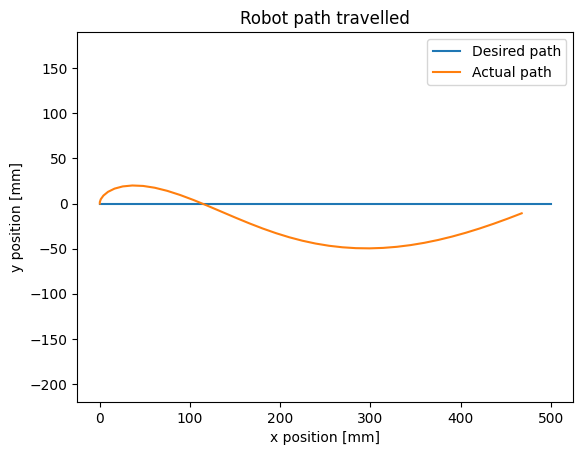

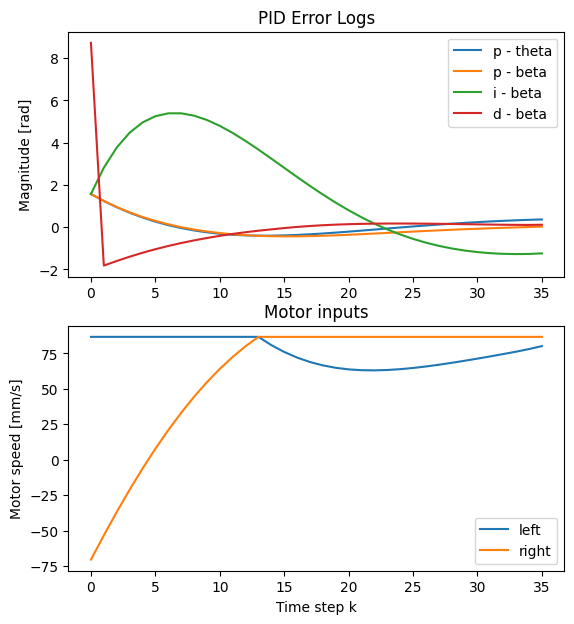

In [23]:
# Plot path
x_log = [state[0] for state in state_log] 
y_log = [state[1] for state in state_log]
theta_log = [state[3] for state in state_log]

plt.plot([start[0], end[0]], [start[1], end[1]])
plt.plot(x_log, y_log)
plt.title("Robot path travelled")
plt.legend(["Desired path", "Actual path"])
plt.axis('equal')
plt.xlabel("x position [mm]")
plt.ylabel('y position [mm]')

# Plot PID error logs
pid.plot()

## [6C] Deep Dive and Explanation
### [6C-1] Choice of Controller
Originally, we had used the Astolfi controller mentioned in class for motion control. We chose this as it was a demonstratedly stable waypoint tracking system with a fairly simple implementation and few constants to tune. However, we observed some performance issues with our implementation of the controller, despite tuning. Some reasons for this were:
- The theoretical Astolfi controller is for a continuous system. We were required to discretize it, and with a fairly slow update frequency (~5 Hz due to motor and CV update times), it became much more difficult to tune the controller to achieve stable and well-performing results.
- The Astolfi controller slows down the velocity of the robot until it comes to a smooth stop at the waypoint. Our path had multiple waypoints, and we wanted to follow it smoothly to the end insead of stopping at each one. We therefore normalized the velocities that were output from the controller to ensure that the robot always travelled at a constant speed. This, however, caused the system to further differ from the expected Astolfi behaviour and caused performance issues such as instability and oscillations.

Due to these issues, we decided to pivot from the base Astolfi controller, and implement a PID controller based on the concepts used in the Astolfi controller. With the normalized velocity, our Astolfi controller had become just a proportional controller, and we hypothesized that the addition of integral and/or derivative terms would help us reduce oscillations and improve path tracking.

### [6C-2] Controller Implementation
The PID controller looks at two separate angle variables: $\theta$, which represents the angle the robot is facing compared to the desired angle at the waypoint, and $\beta$, which represents the angle the robot is facing compared to the angle of the straight line to the goal point. These are the same as the variables $\beta$ and $\alpha$ in the Astolfi controller, simply renamed. 

The controller is therefore managing six different values: the proportional, integral, and derivative errors of both of these variables. The proportional error is simply the difference between the current heading and the variable being compared (angle of waypoint for $\theta$, or angle to goal for $\beta$). The two integral errors are the sum of all previous values of each respective error measurement, and the derivatives are the differences between the current error measurements and the previous ones, divided by the time step. 

Errors are calculated in the following code snippet from the `PID.get_mtr_vels()` function in `motion_control.py`:

In [ ]:
x0, y0, th0 = state[0], state[1], state[3]
x1, y1, th1 = goal

# Calculate theta error - difference between current heading 
# and desired heading at goal
theta_error = th0 - th1

# Keep between [-pi, pi]
if theta_error > np.pi:
    theta_error = theta_error - 2*np.pi
if theta_error < -np.pi:
    theta_error = theta_error + 2*np.pi

# Integral and derivative
self.sum_theta_error += theta_error
theta_error_diff = (theta_error - self.prev_theta_error)/general['dt']

# Calculate beta errors - difference between current heading and 
# direction to goal point
angle_to_goal = np.atan2(y1-y0, x1-x0)
beta_error = th0 - angle_to_goal

# Keep between [-pi, pi]
if beta_error > np.pi:
    beta_error = beta_error - 2*np.pi
if beta_error < -np.pi:
    beta_error = beta_error + 2*np.pi

# Integral and derivative
self.sum_beta_error += beta_error
beta_error_diff = (beta_error - self.prev_beta_error)/general['dt']

The left and right motor velocities are initially set to the same value, our desired normal driving speed. Then, they are each updated (adding to the left, and subtracting from the right) based on the six error calculations - each error parameter is multiplied by its respective PID constant. Finally, these motor values are saturated at a set maximum velocity, to ensure the robot does not go too fast across the small map.

This occurs in the following section of code

In [ ]:
# 'Default' settings
vl = general['drive_vel']
vr = general['drive_vel']

# Proportional control
vl += self.pid_consts['theta']['kp']*theta_error + self.pid_consts['beta']['kp']*beta_error
vr -= self.pid_consts['theta']['kp']*theta_error + self.pid_consts['beta']['kp']*beta_error

# Integral control
vl += self.pid_consts['theta']['ki']*self.sum_theta_error + self.pid_consts['beta']['ki']*self.sum_beta_error
vr -= self.pid_consts['theta']['ki']*self.sum_theta_error + self.pid_consts['beta']['ki']*self.sum_beta_error

# Derivative control
vl += self.pid_consts['theta']['kd']*theta_error_diff + self.pid_consts['beta']['kd']*beta_error_diff
vr -= self.pid_consts['theta']['kd']*theta_error_diff + self.pid_consts['beta']['kd']*beta_error_diff

# Saturate at maximum velocity
if abs(vl) > general['max_vel']:
    vl = np.sign(vl)*general['max_vel']
if abs(vr) > general['max_vel']:
    vr = np.sign(vr)*general['max_vel']

### [6C-3] Tuning
We began the tuning process using the $\beta$ and $\alpha$ constants from the example Astolfi controller online, as a starting reference. The robot took too long to rejoin the path, so we increased the constant for our $\beta$ (Astolfi $\alpha$) until the robot began to join the path quickly, but with some overshoot. We then added a small derivative constant on $\beta$ to correct for this overshoot. At this point, the robot was performing well, but often had a steady state error - travelling at the correct angle, but slightly offset from the line. We therefore added an integral constant to $\beta$ as well to ensure that, as this small steady-state error accumulated, the robot would be inclined to turn back towards the path.

### [6C-4] Example Results
The following two images show the comparison between the robot's ideal path and actual (estimated) path, as well as PID constants and motor inputs for an example path. It can be seen that the robot turns more closely towards the path as the integral sums increase, indicating an improvement over the base proportional controller. Note that integral sums are manually reset to 0 once the robot reaches each waypoint.

![](images/robot-path-example.png) ![](images/pid-output-example.png)

# [7] Conclusion and Sources
## [7A] Conclusion
Overall, this system successfully achieves the goals of the project. The system is able to:
- Identify global obstacles in the environment
- Generate a path from start to goal position which avoids these obstacles
- Guide the robot along the path to the goal without contacting obstacles
- Handle disturbances including local obstacles, kidnapping, and covering of the camera

Future improvements could include more accurate state estimation for improved performance when the camera is covered, optimizing the system to run at higher frequencies, and using a more complex controller for better path tracking performance.
    
## [7B] Sources
- _OpenCV_ — “Camera Calibration and 3D Reconstruction (calib3d module)”. Available online: [https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)  
- _OpenCV_ — “Tutorial: Camera Calibration (Python)”. Available online: [https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html)  
- _OpenCV_ — “Tutorial: Pose Estimation (solvePnP) (Python)”. Available online: [https://docs.opencv.org/4.x/d7/d53/tutorial_py_pose.html](https://docs.opencv.org/4.x/d7/d53/tutorial_py_pose.html)  
- _LearnOpenCV_ — “Contour Detection using OpenCV (Python/C++)”. Available online: [https://learnopencv.com/contour-detection-using-opencv-python-c/](https://learnopencv.com/contour-detection-using-opencv-python-c/)
- _Y. Hu_ — "MTE 544 - Autonomous Mobile Robots", class notes, University of Waterloo, 2024